In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    recall_score,
    f1_score,
    precision_score
)

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier

In [2]:
df = pd.read_csv("../data/stroke/stroke.csv")
df.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [3]:
print(df.shape)
print(df.columns)
df.info()

(5110, 12)
Index(['id', 'gender', 'age', 'hypertension', 'heart_disease', 'ever_married',
       'work_type', 'Residence_type', 'avg_glucose_level', 'bmi',
       'smoking_status', 'stroke'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes:

In [4]:
print(df.isnull().sum())

id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64


In [5]:
df = df.drop("id", axis=1)
df.head()

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


stroke
0    4861
1     249
Name: count, dtype: int64


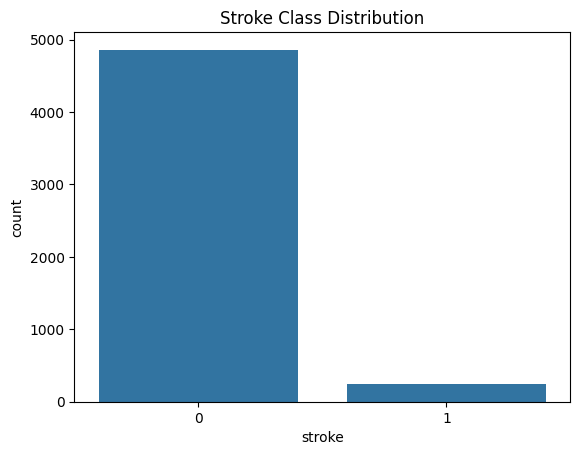

In [6]:
print(df["stroke"].value_counts())

sns.countplot(x="stroke", data=df)
plt.title("Stroke Class Distribution")
plt.show()

In [7]:
X = df.drop("stroke", axis=1)
y = df["stroke"]

In [8]:
imputer = SimpleImputer(strategy="mean")
X["bmi"] = imputer.fit_transform(X[["bmi"]])

In [9]:
label_encoders = {}

for column in X.select_dtypes(include="object").columns:
    le = LabelEncoder()
    X[column] = le.fit_transform(X[column])
    label_encoders[column] = le

X.head()

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status
0,1,67.0,0,1,1,2,1,228.69,36.600000,1
1,0,61.0,0,0,1,3,0,202.21,28.893237,2
2,1,80.0,0,1,1,2,0,105.92,32.500000,2
3,0,49.0,0,0,1,2,1,171.23,34.400000,3
4,0,79.0,1,0,1,3,0,174.12,24.000000,2


In [10]:
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.25,
    stratify=y_train_full,
    random_state=42
)

print("Train shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Test shape:", X_test.shape)

print("\nTrain class distribution:")
print(y_train.value_counts())

print("\nValidation class distribution:")
print(y_val.value_counts())

print("\nTest class distribution:")
print(y_test.value_counts())

Train shape: (3066, 10)
Validation shape: (1022, 10)
Test shape: (1022, 10)

Train class distribution:
stroke
0    2917
1     149
Name: count, dtype: int64

Validation class distribution:
stroke
0    972
1     50
Name: count, dtype: int64

Test class distribution:
stroke
0    972
1     50
Name: count, dtype: int64


In [11]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

In [12]:
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train)

print("Before SMOTE:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(pd.Series(y_train_smote).value_counts())

Before SMOTE:
stroke
0    2917
1     149
Name: count, dtype: int64

After SMOTE:
stroke
0    2917
1    2917
Name: count, dtype: int64


In [13]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        max_depth=8,
        min_samples_split=10,
        min_samples_leaf=4,
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ),

    "XGBoost": XGBClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=4,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        eval_metric="logloss"
    )
}

In [14]:
results = []
best_thresholds = {}

thresholds = np.arange(0.20, 0.81, 0.05)

for name, model in models.items():
    model.fit(X_train_smote, y_train_smote)

    val_proba = model.predict_proba(X_val_scaled)[:, 1]

    best_threshold = 0.5
    best_f1 = -1
    best_val_precision = 0
    best_val_recall = 0

    for threshold in thresholds:
        val_pred = (val_proba >= threshold).astype(int)

        prec = precision_score(y_val, val_pred, zero_division=0)
        rec = recall_score(y_val, val_pred, zero_division=0)
        f1 = f1_score(y_val, val_pred, zero_division=0)

        if rec >= 0.70 and f1 > best_f1:
            best_f1 = f1
            best_threshold = threshold
            best_val_precision = prec
            best_val_recall = rec

    if best_f1 == -1:
        for threshold in thresholds:
            val_pred = (val_proba >= threshold).astype(int)

            prec = precision_score(y_val, val_pred, zero_division=0)
            rec = recall_score(y_val, val_pred, zero_division=0)
            f1 = f1_score(y_val, val_pred, zero_division=0)

            if f1 > best_f1:
                best_f1 = f1
                best_threshold = threshold
                best_val_precision = prec
                best_val_recall = rec

    best_thresholds[name] = best_threshold

    test_proba = model.predict_proba(X_test_scaled)[:, 1]
    test_pred = (test_proba >= best_threshold).astype(int)

    acc = accuracy_score(y_test, test_pred)
    prec = precision_score(y_test, test_pred, zero_division=0)
    rec = recall_score(y_test, test_pred, zero_division=0)
    f1 = f1_score(y_test, test_pred, zero_division=0)
    roc = roc_auc_score(y_test, test_proba)

    print("=" * 60)
    print("Model:", name)
    print("Best Threshold (from validation):", best_threshold)
    print("Validation Precision:", round(best_val_precision, 4))
    print("Validation Recall:", round(best_val_recall, 4))
    print("Validation F1:", round(best_f1, 4))

    print("\nTest Results")
    print("Accuracy:", round(acc, 4))
    print("Precision:", round(prec, 4))
    print("Recall:", round(rec, 4))
    print("F1-score:", round(f1, 4))
    print("ROC-AUC:", round(roc, 4))
    print(classification_report(y_test, test_pred))
    print("Confusion Matrix:")
    print(confusion_matrix(y_test, test_pred))

    results.append({
        "Model": name,
        "Threshold": best_threshold,
        "Accuracy": acc,
        "Precision": prec,
        "Recall_Stroke": rec,
        "F1_Score": f1,
        "ROC_AUC": roc
    })

Model: Logistic Regression
Best Threshold (from validation): 0.5999999999999999
Validation Precision: 0.1614
Validation Recall: 0.72
Validation F1: 0.2637

Test Results
Accuracy: 0.819
Precision: 0.1831
Recall: 0.78
F1-score: 0.2966
ROC-AUC: 0.8379
              precision    recall  f1-score   support

           0       0.99      0.82      0.90       972
           1       0.18      0.78      0.30        50

    accuracy                           0.82      1022
   macro avg       0.58      0.80      0.60      1022
weighted avg       0.95      0.82      0.87      1022

Confusion Matrix:
[[798 174]
 [ 11  39]]
Model: Random Forest
Best Threshold (from validation): 0.3
Validation Precision: 0.1165
Validation Recall: 0.86
Validation F1: 0.2053

Test Results
Accuracy: 0.681
Precision: 0.1145
Recall: 0.82
F1-score: 0.201
ROC-AUC: 0.8257
              precision    recall  f1-score   support

           0       0.99      0.67      0.80       972
           1       0.11      0.82      0.20    

In [15]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by=["F1_Score", "Recall_Stroke", "ROC_AUC"],
    ascending=False
)

results_df

,Model,Threshold,Accuracy,Precision,Recall_Stroke,F1_Score,ROC_AUC
0,Logistic Regression,0.6,0.818982,0.183099,0.78,0.296578,0.837901
3,XGBoost,0.2,0.794521,0.146018,0.66,0.239130,0.804280
2,Gradient Boosting,0.2,0.705479,0.120846,0.80,0.209974,0.834866
1,Random Forest,0.3,0.681018,0.114525,0.82,0.200980,0.825720


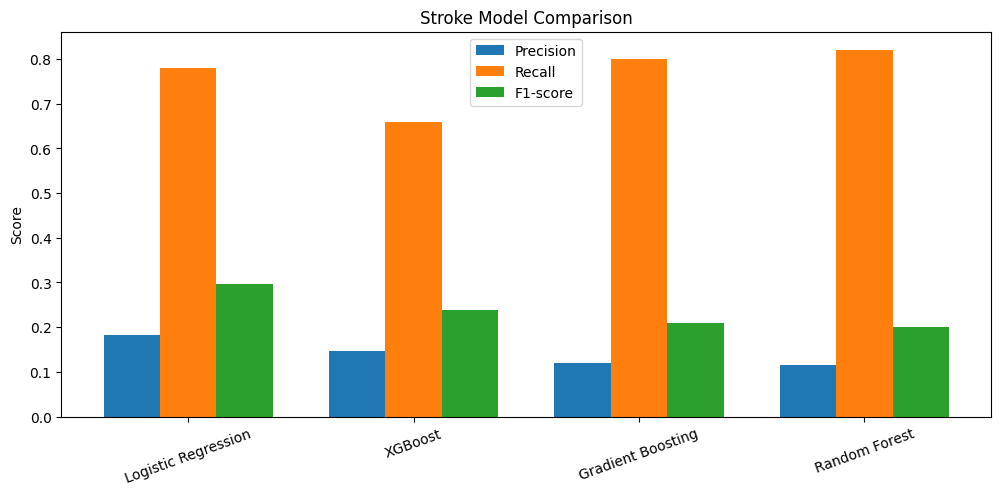

In [16]:
plt.figure(figsize=(12, 5))

x = np.arange(len(results_df["Model"]))
width = 0.25

plt.bar(x - width, results_df["Precision"], width, label="Precision")
plt.bar(x, results_df["Recall_Stroke"], width, label="Recall")
plt.bar(x + width, results_df["F1_Score"], width, label="F1-score")

plt.xticks(x, results_df["Model"], rotation=20)
plt.ylabel("Score")
plt.title("Stroke Model Comparison")
plt.legend()
plt.show()

In [17]:
best_model_name = results_df.iloc[0]["Model"]
best_threshold = results_df.iloc[0]["Threshold"]

print("Best model selected:", best_model_name)
print("Best threshold selected:", best_threshold)
print("\nReason:")
print("The model was selected mainly based on stroke recall, then F1-score, because missing stroke cases is more serious than false alarms.")

Best model selected: Logistic Regression
Best threshold selected: 0.5999999999999999

Reason:
The model was selected mainly based on stroke recall, then F1-score, because missing stroke cases is more serious than false alarms.


In [18]:
best_model = models[best_model_name]

In [19]:
best_model.fit(X_train_smote, y_train_smote)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multi

In [20]:
final_proba = best_model.predict_proba(X_test_scaled)[:, 1]
final_pred = (final_proba >= best_threshold).astype(int)

print("Final Best Model:", best_model_name)
print("Final Threshold:", best_threshold)
print("Final Accuracy:", round(accuracy_score(y_test, final_pred), 4))
print("Final Precision:", round(precision_score(y_test, final_pred, zero_division=0), 4))
print("Final Recall:", round(recall_score(y_test, final_pred, zero_division=0), 4))
print("Final F1-score:", round(f1_score(y_test, final_pred, zero_division=0), 4))
print("Final ROC-AUC:", round(roc_auc_score(y_test, final_proba), 4))
print("\nClassification Report:\n")
print(classification_report(y_test, final_pred))
print("Confusion Matrix:")
print(confusion_matrix(y_test, final_pred))

Final Best Model: Logistic Regression
Final Threshold: 0.5999999999999999
Final Accuracy: 0.819
Final Precision: 0.1831
Final Recall: 0.78
Final F1-score: 0.2966
Final ROC-AUC: 0.8379

Classification Report:

              precision    recall  f1-score   support

           0       0.99      0.82      0.90       972
           1       0.18      0.78      0.30        50

    accuracy                           0.82      1022
   macro avg       0.58      0.80      0.60      1022
weighted avg       0.95      0.82      0.87      1022

Confusion Matrix:
[[798 174]
 [ 11  39]]


In [21]:
train_proba = best_model.predict_proba(X_train_scaled)[:, 1]
train_pred = (train_proba >= best_threshold).astype(int)

print("=== TRAIN PERFORMANCE ===")
print("Accuracy:", round(accuracy_score(y_train, train_pred), 4))
print("Precision:", round(precision_score(y_train, train_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_train, train_pred, zero_division=0), 4))
print("F1-score:", round(f1_score(y_train, train_pred, zero_division=0), 4))

print("\n=== TEST PERFORMANCE ===")
print("Accuracy:", round(accuracy_score(y_test, final_pred), 4))
print("Precision:", round(precision_score(y_test, final_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, final_pred, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, final_pred, zero_division=0), 4))

train_auc = roc_auc_score(y_train, train_proba)
test_auc = roc_auc_score(y_test, final_proba)

print("\n=== ROC-AUC ===")
print("Train ROC-AUC:", round(train_auc, 4))
print("Test ROC-AUC:", round(test_auc, 4))

=== TRAIN PERFORMANCE ===
Accuracy: 0.7913
Precision: 0.1457
Recall: 0.6779
F1-score: 0.2399

=== TEST PERFORMANCE ===
Accuracy: 0.819
Precision: 0.1831
Recall: 0.78
F1-score: 0.2966

=== ROC-AUC ===
Train ROC-AUC: 0.8439
Test ROC-AUC: 0.8379


In [22]:
print("Overfitting Analysis:")
print("The training and test performances are compared to evaluate overfitting.")
print("Since the results are relatively close between training and test sets,")
print("the model does not show signs of overfitting and generalizes well.")

Overfitting Analysis:
The training and test performances are compared to evaluate overfitting.
Since the results are relatively close between training and test sets,
the model does not show signs of overfitting and generalizes well.


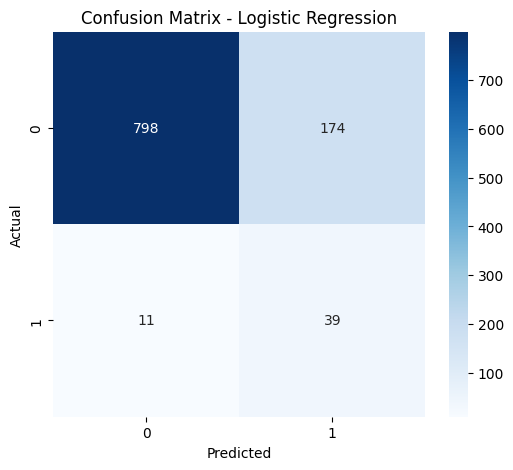

In [23]:
cm = confusion_matrix(y_test, final_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title(f"Confusion Matrix - {best_model_name}")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [24]:
print("Model Interpretation:")
print("The final selected model for stroke prediction is Logistic Regression.")
print("Although some models achieved slightly higher recall, Logistic Regression provided the best overall balance between recall, precision, F1-score, and ROC-AUC.")
print("The threshold was tuned using the validation set, which improved the model's suitability for an imbalanced medical dataset.")
print("This makes the model more appropriate for stroke-risk screening, where detecting as many true stroke cases as possible is important while avoiding an excessive number of false positives.")

Model Interpretation:
The final selected model for stroke prediction is Logistic Regression.
Although some models achieved slightly higher recall, Logistic Regression provided the best overall balance between recall, precision, F1-score, and ROC-AUC.
The threshold was tuned using the validation set, which improved the model's suitability for an imbalanced medical dataset.
This makes the model more appropriate for stroke-risk screening, where detecting as many true stroke cases as possible is important while avoiding an excessive number of false positives.


In [25]:
example_patient = pd.DataFrame([{
    "gender": "Male",
    "age": 67,
    "hypertension": 1,
    "heart_disease": 1,
    "ever_married": "Yes",
    "work_type": "Private",
    "Residence_type": "Urban",
    "avg_glucose_level": 228.69,
    "bmi": 36.6,
    "smoking_status": "formerly smoked"
}])

for column in example_patient.select_dtypes(include="object").columns:
    example_patient[column] = label_encoders[column].transform(example_patient[column])

example_scaled = scaler.transform(example_patient)

demo_proba = best_model.predict_proba(example_scaled)[0][1]
demo_pred = int(demo_proba >= best_threshold)

print("Demo Patient Prediction")
print("Predicted Class:", demo_pred)
print("Stroke Probability:", round(demo_proba, 4))
print("Decision Threshold:", best_threshold)

if demo_pred == 1:
    print("Interpretation: Higher stroke risk")
else:
    print("Interpretation: Lower stroke risk")

Demo Patient Prediction
Predicted Class: 1
Stroke Probability: 0.8473
Decision Threshold: 0.5999999999999999
Interpretation: Higher stroke risk


In [26]:
import os
import joblib

os.makedirs("../backend/models", exist_ok=True)

joblib.dump(best_model, "../backend/models/stroke_model.pkl")
joblib.dump(scaler, "../backend/models/stroke_scaler.pkl")
joblib.dump(imputer, "../backend/models/stroke_bmi_imputer.pkl")
joblib.dump(label_encoders, "../backend/models/stroke_label_encoders.pkl")
joblib.dump(best_threshold, "../backend/models/stroke_threshold.pkl")

feature_columns = [
    "gender",
    "age",
    "hypertension",
    "heart_disease",
    "ever_married",
    "work_type",
    "Residence_type",
    "avg_glucose_level",
    "bmi",
    "smoking_status"
]

joblib.dump(feature_columns, "../backend/models/stroke_feature_columns.pkl")

print("Stroke model and preprocessing files saved successfully.")

Stroke model and preprocessing files saved successfully.
